# 058 — ensemble xgboost mlp refinado

Compara com ensemble 025: XGBoost 007 + MLP 020 (75/25). Usa a configuração escolhida no 057 e seleciona pesos da mistura por CV no treino. MLP 64→32, Adam 0,0001, dropout 0,1, inverse_sqrt e 85 épocas fixas. Inclui modelos individuais nos extremos da grelha.

**Estado: executado pelo runner; resultados locais guardados.** A seleção usa três folds dentro de 8.769 linhas. A validação fixa de 2.193 linhas é desenvolvimento, não teste independente. Nenhum modelo usa AGE_RANGE ou identificadores nas entradas.

058 resultado completo reutilizado após verificar contexto.
Protocolo: CV de desenvolvimento para escolher pesos. A configuração XGBoost já foi selecionada em 057 usando o mesmo treino; estas médias não são uma estimativa independente pós-seleção. A validação fixa não escolhe pesos nem épocas.
Selecionado: {'label': 'xgb057_0.6_mlp_0.4', 'xgb': {'label': 'combinado', 'kind': 'xgb', 'params': {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8}, 'weighting': 'none'}, 'weight': 0.6}
Versões: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}
Duração da corrida original (s), incluindo preparação e avaliação: 43.73470691598777
Diferenças emparelhadas CV: {'differences': [0.007347447546673047, 0.003870592480999413, -0.0017375859468571897], 'mean': 0.003160151360271757, 'std': 0.0045839942554672915}
Por escalão: controlo_025
Por e

,configuração,Macro F1 CV,DP,folds
0,controlo_025_75_25,0.456223,0.007404,"[0.4615031396900763, 0.44776059177748373, 0.45..."
1,xgb057_0_mlp_1,0.443834,0.012284,"[0.45790288447029914, 0.4352320532239305, 0.43..."
2,xgb057_0.25_mlp_0.75,0.458984,0.005985,"[0.4658811638057442, 0.45516372413238293, 0.45..."
3,xgb057_0.5_mlp_0.5,0.458687,0.005986,"[0.4648976057200279, 0.4529537812382458, 0.458..."
4,xgb057_0.6_mlp_0.4,0.459383,0.008737,"[0.4688505872367493, 0.45163118425848314, 0.45..."
5,xgb057_0.75_mlp_0.25,0.456493,0.009185,"[0.4670379979005947, 0.452207822110839, 0.4502..."
6,xgb057_0.9_mlp_0.1,0.452127,0.008376,"[0.4617733884270569, 0.4479137471406511, 0.446..."
7,xgb057_1_mlp_0,0.448959,0.006476,"[0.4563706741093092, 0.4443941639373412, 0.446..."


,modelo,parcela,Macro F1,accuracy
0,controlo_025,train,0.950507,0.940472
1,controlo_025,validation,0.461470,0.465572
2,selecionado,train,0.930239,0.920629
3,selecionado,validation,0.462412,0.465572


,classe,precision,recall,F1,support
0,0,0.765957,0.878049,0.818182,41
1,1,0.500000,0.294118,0.370370,34
2,2,0.578313,0.600000,0.588957,80
3,3,0.380952,0.320000,0.347826,75
4,4,0.357143,0.277778,0.312500,90
5,5,0.314685,0.348837,0.330882,129
6,6,0.376404,0.389535,0.382857,172
7,7,0.427711,0.410405,0.418879,173
8,8,0.585366,0.662983,0.621762,181
9,9,0.606635,0.630542,0.618357,203


,classe,precision,recall,F1,support
0,0,0.840909,0.902439,0.870588,41
1,1,0.478261,0.323529,0.385965,34
2,2,0.552941,0.587500,0.569697,80
3,3,0.333333,0.320000,0.326531,75
4,4,0.328767,0.266667,0.294479,90
5,5,0.320261,0.379845,0.347518,129
6,6,0.371622,0.319767,0.343750,172
7,7,0.372093,0.369942,0.371014,173
8,8,0.595122,0.674033,0.632124,181
9,9,0.647059,0.650246,0.648649,203


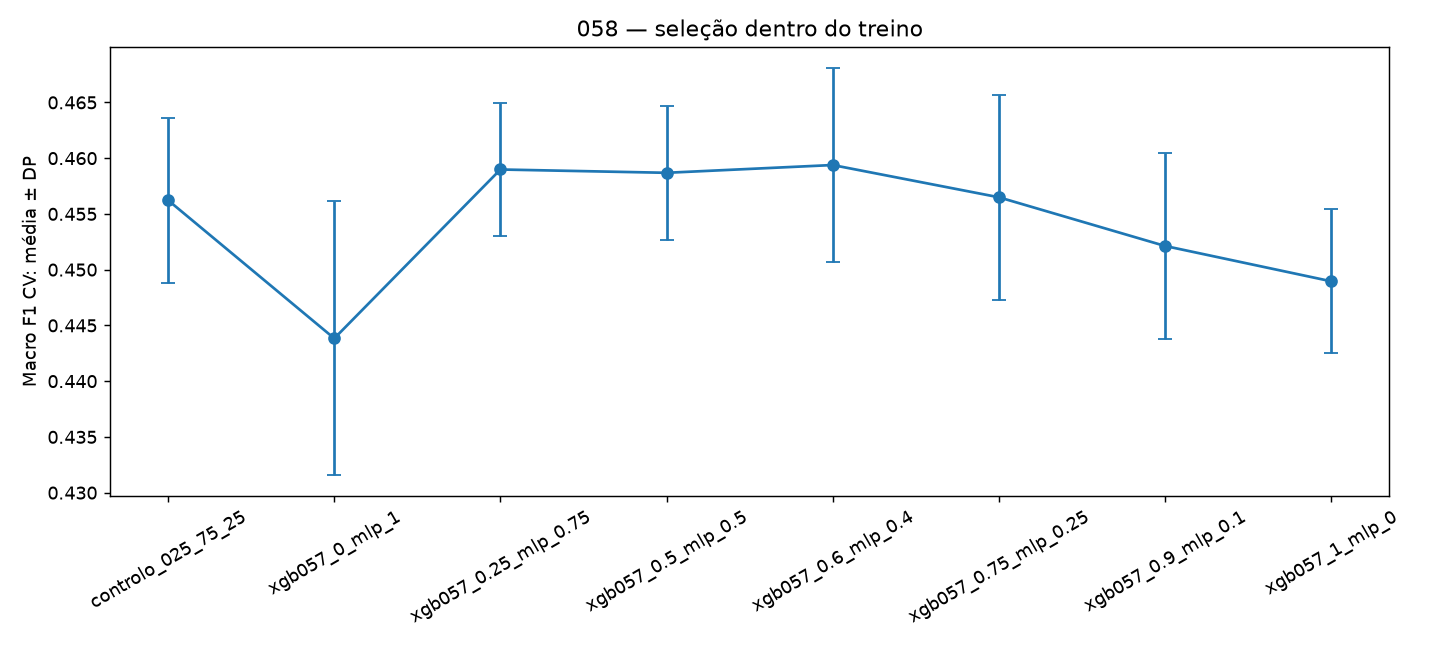

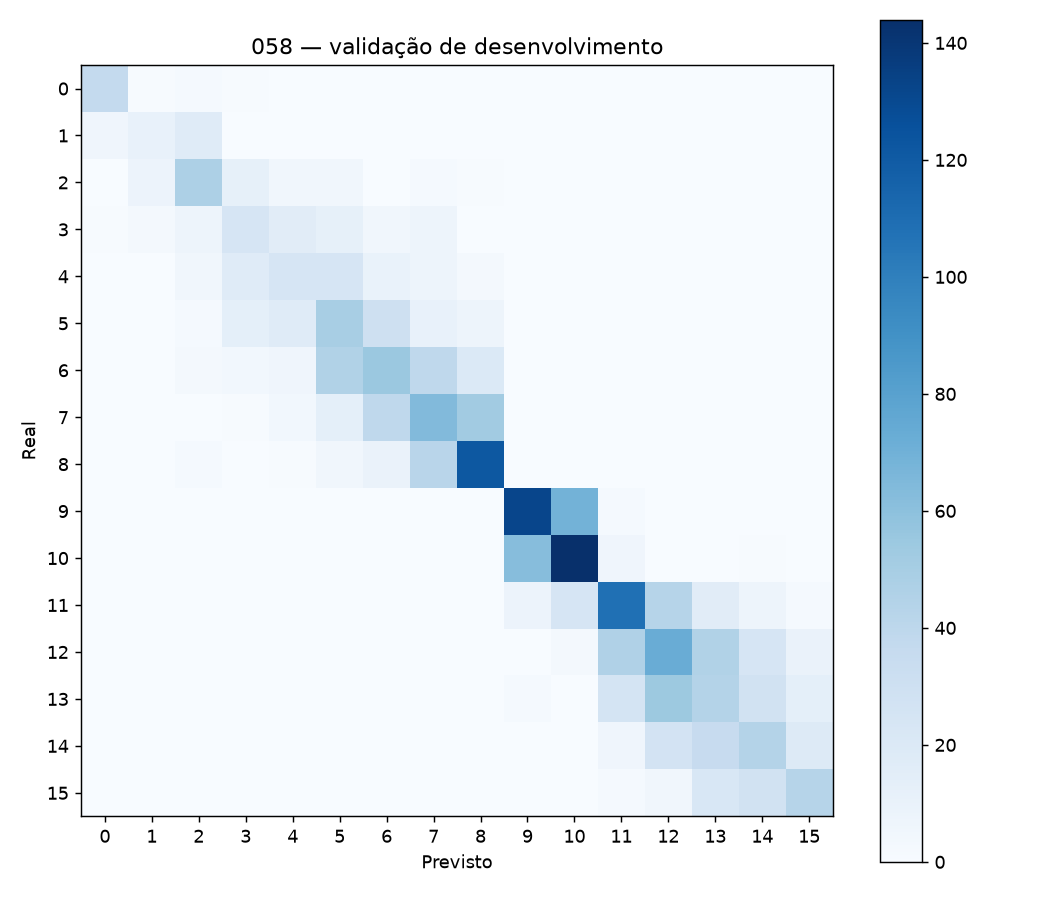

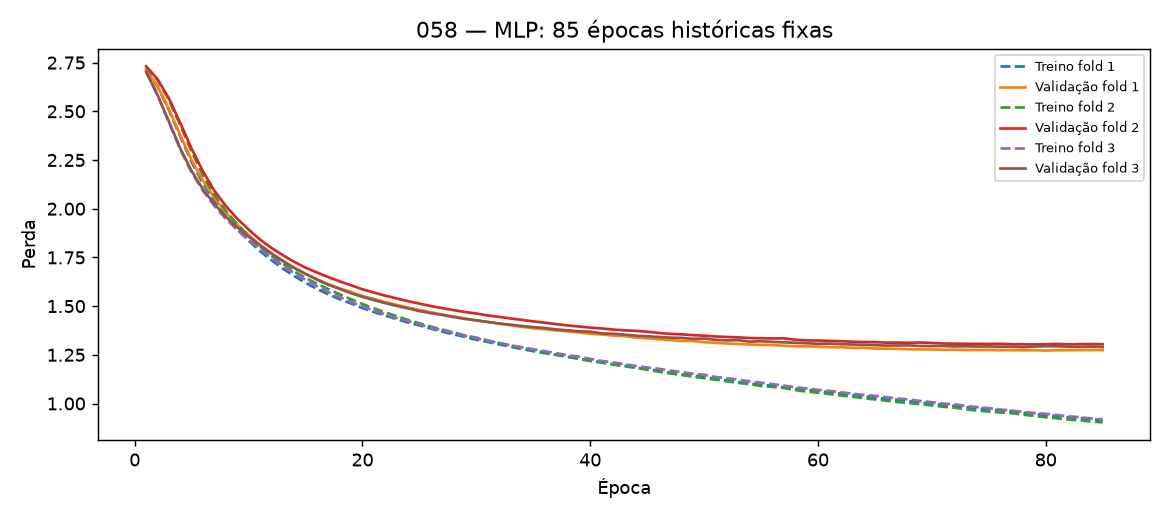

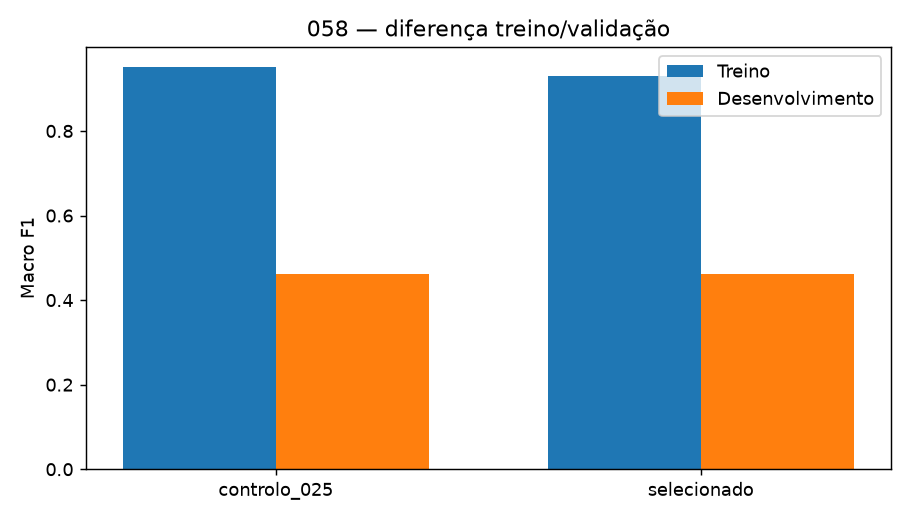

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'src/experiments_056_058.py').exists())
sys.path.insert(0, str(root))
from src.experiments_056_058 import run_experiment
result = run_experiment('058')
print('Protocolo:', result['protocol'])
print('Selecionado:', result['selected']['candidate'])
print('Versões:', result['context']['versions'])
print('Duração da corrida original (s), incluindo preparação e avaliação:', result['seconds'])
print('Diferenças emparelhadas CV:', result['paired_cv'])
display(pd.DataFrame([{'configuração':r['candidate']['label'], 'Macro F1 CV':r['mean'], 'DP':r['std'], 'folds':r['folds']} for r in result['candidates']]))
display(pd.DataFrame([{'modelo':name,'parcela':part,'Macro F1':m['macro_f1'],'accuracy':m['accuracy']} for name,groups in result['fixed'].items() for part,m in groups.items()]))
for name, groups in result['fixed'].items():
    print('Por escalão:', name)
    display(pd.DataFrame(groups['validation']['per_class']))
for p in sorted((root/'reports').glob('experiencia_058_*.png')):
    display(Image(filename=str(p)))
print('CSV:', result['submission'])
print('Kaggle:', result['kaggle_score'])


## Conclusões locais

- Macro F1: **0.4624**; accuracy: **0.4656**.
- Diferença face ao controlo contemporâneo: **+0.0009** no desenvolvimento.
- Seleção CV: `xgb057_0.6_mlp_0.4`; diferença média emparelhada **+0.0032**.
- CSV: `submissions/submission_058_ensemble_xgboost_mlp_refinado.csv`. Motivo se não gerado: [].
- A seleção foi interna. Uma margem pequena ou um CSV distinto não prova melhoria no Kaggle.
- Melhorias seguintes: analisar estabilidade nos folds e os escalões 1, 6 e 13 antes de aumentar a pesquisa.

# Conclusão e Decisão
- Data: 19/11
- Pontuação Kaggle: 0.46
- Melhorias: verificar estabilidade nos mesmos folds e complementaridade dos erros antes de voltar a afinar pesos. Isso já está previsto em 071–073.